# The Main Problem
Volatility is how much a price moves around, We measure it as the variance (or standard deviation) of returns.

## 1. Setup

In [36]:
# 1. Setup

# Importing necessary libraries
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf
from arch import arch_model
import lightgbm as lgb

warnings.filterwarnings("ignore", category=RuntimeWarning)

# --- Settings ------------------------------------------------
TICKER      = "SPY"
START       = "2000-01-01"
END         = None          # None = up to today
H           = 1             # forecast horizon (H trading days)
MIN_TRAIN   = 1000          # ~4 years of data before the first forecast
REFIT_EVERY = 21            # re-train the model every 3 weeks
SEED        = 73            # just a personal preference

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# Importing the plot-style (plot_style.py)
from plot_style import COLORS, STYLES, use_style
use_style() # reads that py file and copies each setting into matplotlib’s global settings, plt.rcParams.

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

## 2. Downloading the data

Let's use free daily data that is available from Yahoo Finance with `yfinance`: Open, High, Low, Close for SPY.

1. For the first time, the data is saved to data/SPY.csv. After that a SAVED copy will be loaded, so our results stay the same each time the notebook is run.
Note: **The CSV file should be deleted to refresh the data**

2. Adjust Prices: On dividend, SPY's price drops by the divident amount.
**this adjustment should not be treated as a risk**. The Open, High, Low, and Close will be scaled by `Adj_Close / Close` so dividends don't look like price moves.

In [37]:
def load_prices(ticker, start, end=None):
    path = DATA_DIR / f"{ticker}.csv"
    # Check if a CSV already exists.
    if path.exists():
        df = pd.read_csv(path, index_col=0, parse_dates=True)
        print(f"Loaded {len(df):,} rows from {path}")
        return df

    # Notes: yfinance is kept inside function as it is time-consuming and we need it only when
    # are storing new data
    import yfinance as yf
    raw = yf.download(ticker, start=start, end=end, auto_adjust=False, progress=False)
    if raw.empty:
        raise RuntimeError("No data downloaded. Check your internet connection and the ticker.")
    if isinstance(raw.columns, pd.MultiIndex):      # newer finance returns (field, ticker) columns
        raw.columns = raw.columns.get_level_values(0)
    df = raw[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].dropna()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "Date"
    df.to_csv(path)
    print(f"Downloaded {len(df):,} rows and saved to {path}")
    return df

raw = load_prices(TICKER, START, END)

# Adjust OHLC for dividends (and splits) using the Adj Close / Close ratio
"""The adjustments happens on the close of business and the $div is subtracted overnight
which is evident in the next day's Open price."""
adj = raw['Adj Close'] / raw["Close"]
px = raw[["Open", "High", "Low", "Close"]].mul(adj, axis=0)

# Basic data checks: bad rows quietly ruin volatility estimates
O, H, L, C = px["Open"], px["High"], px["Low"], px["Close"]
bad = (H < L) | (H < np.maximum(O, C)) | (L > np.minimum(O, C))
px = px[~bad]
print(f"dropped {bad.sum()} bad rows, {len(px):,} trading days from {px.index[0]:%Y-%m-%d} to {px.index[-1]:%Y-%m-%d}")
px.tail()


Downloaded 6,747 rows and saved to data/SPY.csv
dropped 0 bad rows, 6,747 trading days from 2000-01-03 to 2026-10-29


/Users/rsainju/Research/3_ML_practice/0_quant-practice/volatility-forecasting/.venv/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/rsainju/Research/3_ML_practice/0_quant-practice/volatility-forecasting/.venv/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/rsainju/Research/3_ML_practice/0_quant-practice/volatility-forecasting/.venv/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecat

Price,Open,High,Low,Close
Date,,,,
2026-10-23,759.900024,763.469971,758.679993,759.969971
2026-10-26,762.250000,767.729980,761.630005,765.369995
2026-10-27,767.340027,771.140015,765.210022,769.659973
2026-10-28,771.429993,773.359985,769.239990,772.309998
2026-10-29,768.789978,770.760010,766.619995,769.359985


# 4. Traget Building and Realized variance

Volatility has to be estimated rom the prices.  
A. **Squared daily return**: simple, but noisy. It does not capture the fact that a day can swing wildly and close flat.   
B. **Using the day's range**: the High and Low tell us how far the price travelled during the day. Range-based estimators are several times more precise.  

We will use Garman-Klass estimator for, extended with an overnight term (called Garman-Klass-Yang-Zhang) for calculating the Realized Volatility (RV):

$$
RV_t = \underbrace{\left(\ln \tfrac{O_t}{C_{t-1}}\right)^2}_{\text{overnight gap}}
     + \tfrac{1}{2}\underbrace{\left(\ln \tfrac{H_t}{L_t}\right)^2}_{\text{intraday range}}
     - (2\ln 2 - 1)\left(\ln \tfrac{C_t}{O_t}\right)^2
$$

The overnight term matters. It makes $RV_t$ measure the same thing as a close-to-close return, so all our
models (including GARCH, which only sees close-to-close returns) are forecasting the same quantity.

**Units.** We work with returns in percent, so variance is in %². For plots, we convert to
**annualized volatility in %**: $\sqrt{252 \cdot RV}$. (SPY's long-run level is roughly 15–20%.)


In [38]:
"""Let's calculate the RV_t value"""
O, H, L, C = px["Open"], px["High"], px["Low"], px["Close"]
r = 100 * np.log(C).diff()        # Daily log return, in %
# Garman-Klass with a overnight term: gap^2 + 0.5 range^2 - (2*ln2 - 1) body^2, in %^2
overnight = np.log(O / C.shift(1))
hl = np.log(H / L)
co = np.log(C / O)
rv = 1e4 * (overnight**2 + 0.5 * hl**2 - (2*np.log(2) - 1) * co**2)
  
floor = rv[rv > 0].quantile(0.001)    # guard against zero-range days | log(0) = -inf
rv = rv.clip(lower=floor) # a few have zero range, keep RV strictly positive (we take logs later)

data = pd.DataFrame({"r": r, "rv": rv}).dropna()
to_ann_vol = lambda var: np.sqrt(252 * var)         # %^2 per day -> annualized vol in %

print(f"Average annualized vol from RV:            {to_ann_vol(data.rv.mean()):.1f}%")
print(f"Average annualized vol from squared returns: {to_ann_vol((data.r**2).mean()):.1f}%  (should be close)")


Average annualized vol from RV:            19.5%
Average annualized vol from squared returns: 19.2%  (should be close)


# 5. Look before you model: three stylized facts

Every model choice later should trace back to something we see here

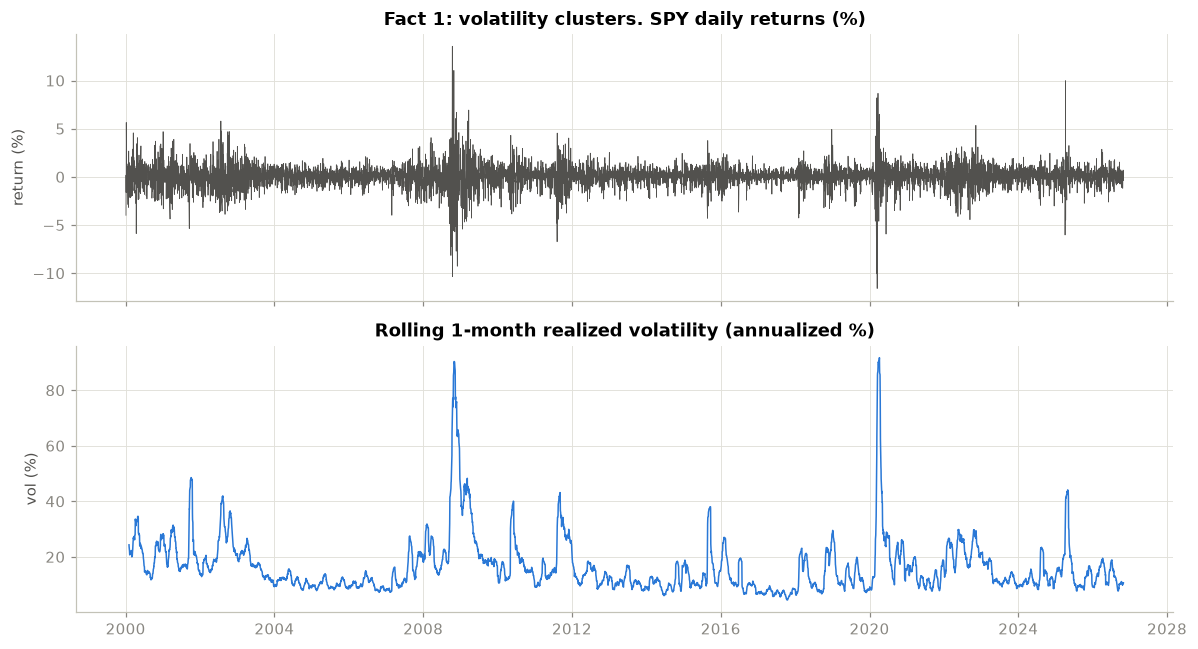

In [39]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(data.r, color=COLORS["Realized"], lw=0.5)
ax[0].set(title=f"Fact 1: volatility clusters. {TICKER} daily returns (%)", ylabel="return (%)")
vol22 = to_ann_vol(data.rv.rolling(22).mean()) # 22 days rolling mean
ax[1].plot(vol22, color=COLORS["HAR"], lw=1)
ax[1].set(title="Rolling 1-month realized volatility (annualized %)", ylabel="vol (%)")
savefig("01_returns_and_volatility")


In [40]:
print(100 * np.log(px["Close"]), 
      100 * np.log(px["Close"]).diff())

Date
2000-01-03    450.983740
2000-01-04    446.994529
2000-01-05    447.173287
2000-01-06    445.553119
2000-01-07    451.198350
                 ...    
2026-10-23    663.327892
2026-10-26    664.035937
2026-10-27    664.594882
2026-10-28    664.938602
2026-10-29    664.555898
Name: Close, Length: 6747, dtype: float64 Date
2000-01-03         NaN
2000-01-04   -3.989211
2000-01-05    0.178758
2000-01-06   -1.620168
2000-01-07    5.645231
                ...   
2026-10-23   -0.523654
2026-10-26    0.708045
2026-10-27    0.558945
2026-10-28    0.343720
2026-10-29   -0.382704
Name: Close, Length: 6747, dtype: float64


In [41]:
[1,2,3].quantile(0.0001)


AttributeError: 'list' object has no attribute 'quantile'